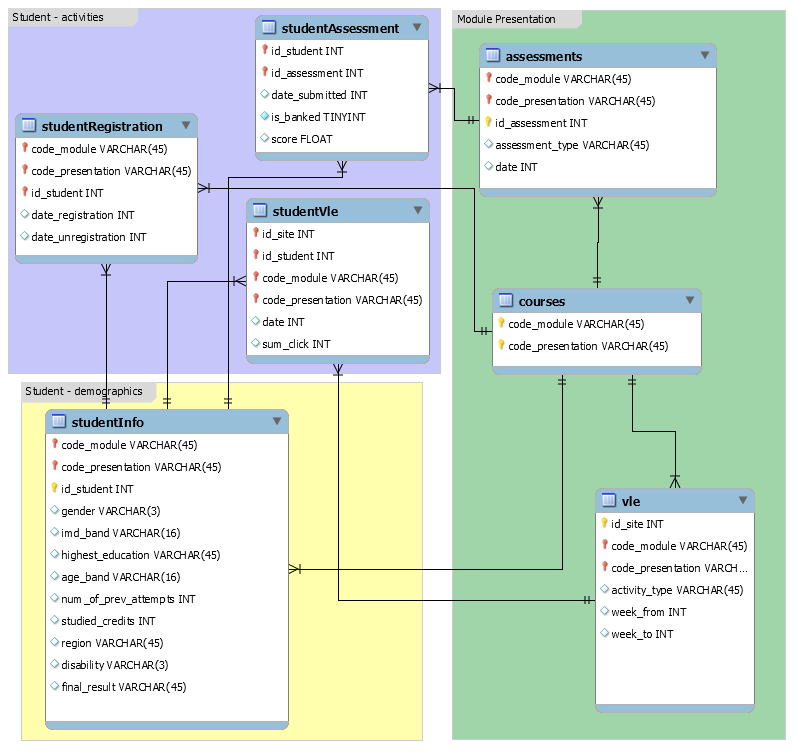

In [1]:
#Schema Involved
from IPython.display import Image
Image("../docs/model.png")

NẠP THƯ VIỆN VÀ ĐỊNH NGHĨA HÀM KIỂM TRA CƠ BẢN

In [2]:
# Khai báo thư viện cốt lõi và cấu hình trực quan hóa
import os
import sys
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%matplotlib inline
warnings.filterwarnings('ignore')

# Thiết lập đường dẫn chuẩn từ vị trí notebook (lùi 1 cấp ra oulad_project)
PROJECT_ROOT = os.path.abspath('..')
DATA_DIR = os.path.join(PROJECT_ROOT, 'data', 'raw')
PROCESSED_DIR = os.path.join(PROJECT_ROOT, 'data', 'processed')
RESULTS_DIR = os.path.join(PROJECT_ROOT, 'results')

# Tạo sẵn các thư mục đầu ra nếu chưa có
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print(f"Thư mục gốc: {PROJECT_ROOT}")
print(f"Thư mục data/raw: {DATA_DIR}")

Thư mục gốc: d:\Ki7\BigData\OULAD_learning_analytics
Thư mục data/raw: d:\Ki7\BigData\OULAD_learning_analytics\data\raw


In [3]:
#Hàm hiển thị báo cáo thông tin cơ bản của DataFrame
def show_basic_info(df, name="DATAFRAME"):
  print("=" * 80)
  print(f"BÁO CÁO CẤU TRÚC: {name}")
  print("-" * 80)
  print("HEAD (3 dòng đầu):")
  display(df.head(3))
  print("-" * 80)
  print(f"SHAPE: {df.shape[0]:,} dòng x {df.shape[1]} cột")
  print("-" * 80)
  print("INFO:")
  df.info()
  print("-" * 80)
  print("DESCRIBE (Thống kê mô tả số):")
  display(df.describe())
  print("=" * 80)

NHIỆM VỤ 1: THIẾT LẬP MÔI TRƯỜNG, KIỂM KÊ 7 BẢNG VÀ TỐI ƯU HÓA BỘ NHỚ RAM

In [4]:
#Đọc bảng assessments.csv và chuẩn hóa cột date
assessments_df = pd.read_csv(
    os.path.join(DATA_DIR, 'assessments.csv'),
    na_values=['?', ' ', '', 'NaN', 'null', 'None']
)
assessments_df['date'] = pd.to_numeric(assessments_df['date'], errors='coerce')

show_basic_info(assessments_df, "assessments_df")

BÁO CÁO CẤU TRÚC: assessments_df
--------------------------------------------------------------------------------
HEAD (3 dòng đầu):


,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19.0,10.0
1,AAA,2013J,1753,TMA,54.0,20.0
2,AAA,2013J,1754,TMA,117.0,20.0


--------------------------------------------------------------------------------
SHAPE: 206 dòng x 6 cột
--------------------------------------------------------------------------------
INFO:
<class 'pandas.DataFrame'>
RangeIndex: 206 entries, 0 to 205
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   code_module        206 non-null    str    
 1   code_presentation  206 non-null    str    
 2   id_assessment      206 non-null    int64  
 3   assessment_type    206 non-null    str    
 4   date               195 non-null    float64
 5   weight             206 non-null    float64
dtypes: float64(2), int64(1), str(3)
memory usage: 12.0 KB
--------------------------------------------------------------------------------
DESCRIBE (Thống kê mô tả số):


,id_assessment,date,weight
count,206.000000,195.000000,206.000000
mean,26473.975728,145.005128,20.873786
std,10098.625521,76.001119,30.384224
min,1752.000000,12.000000,0.000000
25%,15023.250000,71.000000,0.000000
50%,25364.500000,152.000000,12.500000
75%,34891.750000,222.000000,24.250000
max,40088.000000,261.000000,100.000000


In [5]:
#Bảng courses.csv (Danh mục khóa học và kỳ học)
courses_df = pd.read_csv(os.path.join(DATA_DIR, "courses.csv"))
show_basic_info(courses_df, "courses_df")

BÁO CÁO CẤU TRÚC: courses_df
--------------------------------------------------------------------------------
HEAD (3 dòng đầu):


,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013J,268


--------------------------------------------------------------------------------
SHAPE: 22 dòng x 3 cột
--------------------------------------------------------------------------------
INFO:
<class 'pandas.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 3 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   code_module                 22 non-null     str  
 1   code_presentation           22 non-null     str  
 2   module_presentation_length  22 non-null     int64
dtypes: int64(1), str(2)
memory usage: 836.0 bytes
--------------------------------------------------------------------------------
DESCRIBE (Thống kê mô tả số):


,module_presentation_length
count,22.000000
mean,255.545455
std,13.654677
min,234.000000
25%,241.000000
50%,261.500000
75%,268.000000
max,269.000000


In [6]:
#Đọc và chuẩn hóa kiểu dữ liệu cho bảng studentAssessment.csv
studentAssessment_df = pd.read_csv(
    os.path.join(DATA_DIR, 'studentAssessment.csv'),
    na_values=['?', ' ', '', 'NaN', 'null', 'None']
)

# Ép cột score về kiểu số thực, các ô trống/ký tự lạ sẽ tự động thành NaN
studentAssessment_df['score'] = pd.to_numeric(studentAssessment_df['score'], errors='coerce')

show_basic_info(studentAssessment_df, "studentAssessment_df")

BÁO CÁO CẤU TRÚC: studentAssessment_df
--------------------------------------------------------------------------------
HEAD (3 dòng đầu):


,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78.0
1,1752,28400,22,0,70.0
2,1752,31604,17,0,72.0


--------------------------------------------------------------------------------
SHAPE: 173,912 dòng x 5 cột
--------------------------------------------------------------------------------
INFO:
<class 'pandas.DataFrame'>
RangeIndex: 173912 entries, 0 to 173911
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id_assessment   173912 non-null  int64  
 1   id_student      173912 non-null  int64  
 2   date_submitted  173912 non-null  int64  
 3   is_banked       173912 non-null  int64  
 4   score           173739 non-null  float64
dtypes: float64(1), int64(4)
memory usage: 6.6 MB
--------------------------------------------------------------------------------
DESCRIBE (Thống kê mô tả số):


,id_assessment,id_student,date_submitted,is_banked,score
count,173912.000000,1.739120e+05,173912.000000,173912.000000,173739.000000
mean,26553.803556,7.051507e+05,116.032942,0.010977,75.799573
std,8829.784254,5.523952e+05,71.484148,0.104194,18.798107
min,1752.000000,6.516000e+03,-11.000000,0.000000,0.000000
25%,15022.000000,5.044290e+05,51.000000,0.000000,65.000000
50%,25359.000000,5.852080e+05,116.000000,0.000000,80.000000
75%,34883.000000,6.344980e+05,173.000000,0.000000,90.000000
max,37443.000000,2.698588e+06,608.000000,1.000000,100.000000


In [7]:
# Bảng studentInfo.csv (Nhân khẩu học và kết quả cuối kỳ)
studentInfo_df = pd.read_csv(
    os.path.join(DATA_DIR, "studentInfo.csv"),
    na_values=['?', ' ', '', 'NaN', 'null', 'None']
)
show_basic_info(studentInfo_df, "studentInfo_df")

BÁO CÁO CẤU TRÚC: studentInfo_df
--------------------------------------------------------------------------------
HEAD (3 dòng đầu):


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn


--------------------------------------------------------------------------------
SHAPE: 32,593 dòng x 12 cột
--------------------------------------------------------------------------------
INFO:
<class 'pandas.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   code_module           32593 non-null  str  
 1   code_presentation     32593 non-null  str  
 2   id_student            32593 non-null  int64
 3   gender                32593 non-null  str  
 4   region                32593 non-null  str  
 5   highest_education     32593 non-null  str  
 6   imd_band              31482 non-null  str  
 7   age_band              32593 non-null  str  
 8   num_of_prev_attempts  32593 non-null  int64
 9   studied_credits       32593 non-null  int64
 10  disability            32593 non-null  str  
 11  final_result          32593 non-null  str  
dtypes: int64(3), st

,id_student,num_of_prev_attempts,studied_credits
count,3.259300e+04,32593.000000,32593.000000
mean,7.066877e+05,0.163225,79.758691
std,5.491673e+05,0.479758,41.071900
min,3.733000e+03,0.000000,30.000000
25%,5.085730e+05,0.000000,60.000000
50%,5.903100e+05,0.000000,60.000000
75%,6.444530e+05,0.000000,120.000000
max,2.716795e+06,6.000000,655.000000


In [8]:
#Đọc và chuẩn hóa kiểu dữ liệu cho bảng studentRegistration.csv
studentRegistration_df = pd.read_csv(
    os.path.join(DATA_DIR, 'studentRegistration.csv'),
    na_values=['?', ' ', '', 'NaN', 'null', 'None']
)

# Ép 2 cột ngày về kiểu số thực (float64), các ký tự '?' sẽ tự động thành NaN
studentRegistration_df['date_registration'] = pd.to_numeric(studentRegistration_df['date_registration'], errors='coerce')
studentRegistration_df['date_unregistration'] = pd.to_numeric(studentRegistration_df['date_unregistration'], errors='coerce')

show_basic_info(studentRegistration_df, "studentRegistration_df")

BÁO CÁO CẤU TRÚC: studentRegistration_df
--------------------------------------------------------------------------------
HEAD (3 dòng đầu):


,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159.0,NaN
1,AAA,2013J,28400,-53.0,NaN
2,AAA,2013J,30268,-92.0,12.0


--------------------------------------------------------------------------------
SHAPE: 32,593 dòng x 5 cột
--------------------------------------------------------------------------------
INFO:
<class 'pandas.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   code_module          32593 non-null  str    
 1   code_presentation    32593 non-null  str    
 2   id_student           32593 non-null  int64  
 3   date_registration    32548 non-null  float64
 4   date_unregistration  10072 non-null  float64
dtypes: float64(2), int64(1), str(2)
memory usage: 1.5 MB
--------------------------------------------------------------------------------
DESCRIBE (Thống kê mô tả số):


,id_student,date_registration,date_unregistration
count,3.259300e+04,32548.000000,10072.000000
mean,7.066877e+05,-69.411300,49.757645
std,5.491673e+05,49.260522,82.460890
min,3.733000e+03,-322.000000,-365.000000
25%,5.085730e+05,-100.000000,-2.000000
50%,5.903100e+05,-57.000000,27.000000
75%,6.444530e+05,-29.000000,109.000000
max,2.716795e+06,167.000000,444.000000


In [9]:
#Đọc và chuẩn hóa kiểu dữ liệu cho bảng vle.csv
vle_df = pd.read_csv(
    os.path.join(DATA_DIR, 'vle.csv'),
    na_values=['?', ' ', '', 'NaN', 'null', 'None']
)

# Ép 2 cột tuần về kiểu số thực (float64), các ký tự '?' sẽ tự động thành NaN
vle_df['week_from'] = pd.to_numeric(vle_df['week_from'], errors='coerce')
vle_df['week_to'] = pd.to_numeric(vle_df['week_to'], errors='coerce')

show_basic_info(vle_df, "vle_df")

BÁO CÁO CẤU TRÚC: vle_df
--------------------------------------------------------------------------------
HEAD (3 dòng đầu):


,id_site,code_module,code_presentation,activity_type,week_from,week_to
0,546943,AAA,2013J,resource,NaN,NaN
1,546712,AAA,2013J,oucontent,NaN,NaN
2,546998,AAA,2013J,resource,NaN,NaN


--------------------------------------------------------------------------------
SHAPE: 6,364 dòng x 6 cột
--------------------------------------------------------------------------------
INFO:
<class 'pandas.DataFrame'>
RangeIndex: 6364 entries, 0 to 6363
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_site            6364 non-null   int64  
 1   code_module        6364 non-null   str    
 2   code_presentation  6364 non-null   str    
 3   activity_type      6364 non-null   str    
 4   week_from          1121 non-null   float64
 5   week_to            1121 non-null   float64
dtypes: float64(2), int64(1), str(3)
memory usage: 393.3 KB
--------------------------------------------------------------------------------
DESCRIBE (Thống kê mô tả số):


,id_site,week_from,week_to
count,6.364000e+03,1121.000000,1121.000000
mean,7.260991e+05,15.204282,15.214987
std,1.283151e+05,8.792865,8.779806
min,5.267210e+05,0.000000,0.000000
25%,6.615928e+05,8.000000,8.000000
50%,7.300965e+05,15.000000,15.000000
75%,8.140162e+05,22.000000,22.000000
max,1.077905e+06,29.000000,29.000000


Đọc tối ưu bảng lớn studentVle.csv (Tránh tràn 8 GiB RAM)

Mục đích: File studentVle.csv rất nặng. Chúng ta chỉ định rõ kiểu dữ liệu int16, int32, category để giảm mức tiêu thụ RAM từ gần 2 GB xuống còn dưới 300 MB.

In [10]:
# Đọc studentVle bằng cách chỉ định rõ các cột cần dùng và downcasting kiểu dữ liệu
vle_cols = ['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click']
vle_dtypes = {
    'code_module': 'category',
    'code_presentation': 'category',
    'id_student': np.int32,
    'id_site': np.int32,
    'date': np.int16,
    'sum_click': np.int16
}

studentVle_df = pd.read_csv(
    os.path.join(DATA_DIR, 'studentVle.csv'),
    usecols=vle_cols,
    dtype=vle_dtypes
)

# Kiểm tra dung lượng RAM thực tế sau khi tối ưu
ram_mb = studentVle_df.memory_usage(deep=True).sum() / (1024 ** 2)
print("=" * 80)
print(f"BÁO CÁO CẤU TRÚC: studentVle_df (ĐÃ TỐI ƯU HÓA RAM)")
print("-" * 80)
print(f"SHAPE: {studentVle_df.shape[0]:,} dòng x {studentVle_df.shape[1]} cột")
print(f"Dung lượng RAM chiếm dụng: {ram_mb:.2f} MB")
print("-" * 80)
display(studentVle_df.head(3))
print("=" * 80)

BÁO CÁO CẤU TRÚC: studentVle_df (ĐÃ TỐI ƯU HÓA RAM)
--------------------------------------------------------------------------------
SHAPE: 10,655,280 dòng x 6 cột
Dung lượng RAM chiếm dụng: 142.26 MB
--------------------------------------------------------------------------------


,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1


Khai báo bộ khóa chính và kiểm tra tính duy nhất (Checklist mục 1 & 2)

Mục đích: Kiểm tra quy tắc "Mỗi lượt đăng ký đúng một dòng" và đảm bảo dùng đủ bộ 3 khóa: id_student, code_module, code_presentation.

In [11]:
# Bộ ba khóa chính duy nhất định danh mỗi lượt học (Enrollment level)
KEY_COLS = ['id_student', 'code_module', 'code_presentation']

# Kiểm tra trùng lặp khóa chính trên studentInfo_df và studentRegistration_df
dup_info = studentInfo_df.duplicated(subset=KEY_COLS).sum()
dup_reg = studentRegistration_df.duplicated(subset=KEY_COLS).sum()

print("=" * 80)
print("KIỂM TRA TÍNH TOÀN VẸN CỦA BỘ KHÓA CHÍNH:")
print(f"- Số dòng trùng lặp trên studentInfo: {dup_info}")
print(f"- Số dòng trùng lặp trên studentRegistration: {dup_reg}")

# Khẳng định dữ liệu sạch, không trùng lặp
assert dup_info == 0, "LỖI: Phát hiện trùng lặp khóa trên studentInfo!"
assert dup_reg == 0, "LỖI: Phát hiện trùng lặp khóa trên studentRegistration!"
print("=> XÁC NHẬN: Mỗi lượt đăng ký là một dòng duy nhất (Đạt tiêu chuẩn Checklist mục 1 & 2).")
print("=" * 80)

KIỂM TRA TÍNH TOÀN VẸN CỦA BỘ KHÓA CHÍNH:
- Số dòng trùng lặp trên studentInfo: 0
- Số dòng trùng lặp trên studentRegistration: 0
=> XÁC NHẬN: Mỗi lượt đăng ký là một dòng duy nhất (Đạt tiêu chuẩn Checklist mục 1 & 2).


NHIỆM VỤ 2: LỌC COHORT NGÀY 28 & TẠO CỘT NHÃN MỤC TIÊU

In [12]:
#Thiết lập tham số mốc cắt và ghép bảng đăng ký ban đầu (enrollment)
# 1. Khai báo tham số mốc ngày cắt dữ liệu 
CUTOFF_DAY = 28

# 2. Tạo bảng enrollment gốc bằng cách ghép studentInfo_df và studentRegistration_df
# Bắt buộc ghép đủ bộ 3 khóa chính 
enrollment_raw = pd.merge(
    studentInfo_df,
    studentRegistration_df[['code_module', 'code_presentation', 'id_student', 'date_registration', 'date_unregistration']],
    on=KEY_COLS,
    how='inner'
)

print(f"Tổng số lượt đăng ký ban đầu: {len(enrollment_raw):,} dòng")

Tổng số lượt đăng ký ban đầu: 32,593 dòng


In [13]:
# Tách nhóm rút sớm và loại bỏ các cột nguy cơ rò rỉ dữ liệu
# 1. Lọc nhóm sinh viên rút lui sớm trước CUTOFF_DAY
early_withdrawn_mask = (enrollment_raw['date_unregistration'].notna()) & (enrollment_raw['date_unregistration'] < CUTOFF_DAY)
excluded_early_withdrawn = enrollment_raw[early_withdrawn_mask].copy()

# 2. Loại bỏ 3 cột tránh rò rỉ dữ liệu
leakage_cols = ['final_result', 'date_registration', 'date_unregistration']
excluded_early_withdrawn.drop(columns=[col for col in leakage_cols if col in excluded_early_withdrawn.columns], inplace=True)

# 3. Chỉ xuất duy nhất vào thư mục data/processed
early_save_path = os.path.join(PROCESSED_DIR, "excluded_early_withdrawn.csv")
excluded_early_withdrawn.to_csv(early_save_path, index=False)

print("=" * 80)
print(f"XỬ LÝ VÀ XUẤT FILE EXCLUDED_EARLY_WITHDRAWN THÀNH CÔNG:")
print(f"- Số lượt rút sớm: {len(excluded_early_withdrawn):,} dòng")
print(f"- Số cột còn lại: {excluded_early_withdrawn.shape[1]} cột")
print(f"- Các cột đã loại bỏ: {leakage_cols}")
print(f"- File lưu tại: {early_save_path}")
print("=" * 80)
display(excluded_early_withdrawn.head(3))

XỬ LÝ VÀ XUẤT FILE EXCLUDED_EARLY_WITHDRAWN THÀNH CÔNG:
- Số lượt rút sớm: 5,040 dòng
- Số cột còn lại: 11 cột
- Các cột đã loại bỏ: ['final_result', 'date_registration', 'date_unregistration']
- File lưu tại: d:\Ki7\BigData\OULAD_learning_analytics\data\processed\excluded_early_withdrawn.csv


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y
125,AAA,2013J,292923,F,South East Region,A Level or Equivalent,90-100%,35-55,0,180,N
136,AAA,2013J,305539,F,Wales,Lower Than A Level,80-90%,0-35,0,120,N


In [14]:
#Lọc Cohort chính thức và tạo nhãn label_withdrawn
# 1. Lọc Cohort ngày 28: date_unregistration trống HOẶC >= CUTOFF_DAY
cohort_mask = enrollment_raw['date_unregistration'].isna() | (enrollment_raw['date_unregistration'] >= CUTOFF_DAY)
cohort_df = enrollment_raw[cohort_mask].copy()

# 2. Tạo nhãn nhị phân label_withdrawn: 1 nếu final_result là 'Withdrawn', ngược lại là 0
cohort_df['label_withdrawn'] = (cohort_df['final_result'] == 'Withdrawn').astype(np.int8)

print("=" * 80)
print(f"BÁO CÁO COHORT NGÀY {CUTOFF_DAY}:")
print(f"- Quy mô Cohort chính thức: {len(cohort_df):,} dòng")
print(f"- Kiểm tra tính toán: {len(enrollment_raw):,} = {len(cohort_df):,} (Cohort) + {len(excluded_early_withdrawn):,} (Rút sớm)")
assert len(enrollment_raw) == len(cohort_df) + len(excluded_early_withdrawn), "LỖI: Sai lệch số lượng dòng khi tách Cohort!"
print("=" * 80)

BÁO CÁO COHORT NGÀY 28:
- Quy mô Cohort chính thức: 27,553 dòng
- Kiểm tra tính toán: 32,593 = 27,553 (Cohort) + 5,040 (Rút sớm)


In [15]:
#Báo cáo thống kê quy mô Cohort và tỷ lệ nhãn dương
# Thống kê tổng quan nhãn trên toàn bộ Cohort
total_cohort = len(cohort_df)
pos_count = cohort_df['label_withdrawn'].sum()
pos_rate = cohort_df['label_withdrawn'].mean()

print(f"Tổng số sinh viên trong Cohort: {total_cohort:,}")
print(f"Số sinh viên rút lui sau ngày {CUTOFF_DAY} (Lớp 1): {pos_count:,} ({pos_rate * 100:.2f}%)")
print(f"Số sinh viên hoàn thành khóa học (Lớp 0): {total_cohort - pos_count:,} ({(1 - pos_rate) * 100:.2f}%)")
print("-" * 80)

# Thống kê chi tiết tỷ lệ rút lui theo từng môn học (code_module)
module_report = cohort_df.groupby('code_module', observed=False)['label_withdrawn'].agg(
    Tong_sinh_vien='count',
    So_rut_lui='sum',
    Ti_le_rut_lui='mean'
).reset_index()

module_report['Ti_le_rut_lui'] = (module_report['Ti_le_rut_lui'] * 100).round(2).astype(str) + ' %'
print("TỶ LỆ RÚT LUI THEO TỪNG MÔN HỌC (MODULE):")
display(module_report)
print("=" * 80)

Tổng số sinh viên trong Cohort: 27,553
Số sinh viên rút lui sau ngày 28 (Lớp 1): 5,124 (18.60%)
Số sinh viên hoàn thành khóa học (Lớp 0): 22,429 (81.40%)
--------------------------------------------------------------------------------
TỶ LỆ RÚT LUI THEO TỪNG MÔN HỌC (MODULE):


,code_module,Tong_sinh_vien,So_rut_lui,Ti_le_rut_lui
0,AAA,718,96,13.37 %
1,BBB,6435,916,14.23 %
2,CCC,3523,1064,30.2 %
3,DDD,5287,1268,23.98 %
4,EEE,2553,341,13.36 %
5,FFF,6599,1243,18.84 %
6,GGG,2438,196,8.04 %


NHIỆM VỤ 3:TRÍCH XUẤT ĐẶC TRƯNG HÀNH VI TƯƠNG TÁC VLE (NGÀY 0–27)

In [16]:
# 1. Lọc tương tác trước mốc CUTOFF_DAY (date < 28) TRƯỚC để giảm dữ liệu, tiết kiệm RAM
vle_filtered = studentVle_df[studentVle_df['date'] < CUTOFF_DAY].copy()

# 2. Sau đó mới ghép với vle_df để lấy activity_type
valid_vle = pd.merge(
    vle_filtered,
    vle_df[['id_site', 'activity_type']],
    on='id_site',
    how='left'
)
del vle_filtered  # Giải phóng RAM

print(f"Tổng số bản ghi VLE trước ngày {CUTOFF_DAY}: {len(valid_vle):,} dòng")

Tổng số bản ghi VLE trước ngày 28: 2,801,311 dòng


In [17]:
#Hàm tính chuỗi ngày nghỉ dài nhất (longest_gap_days)
def compute_longest_gap(dates_series, cutoff=CUTOFF_DAY):
    """
    Tính chuỗi ngày liên tiếp không có tương tác click nào trong khoảng [0, cutoff - 1].
    """
    # Lọc các ngày hợp lệ trong kỳ học [0, cutoff - 1]
    active_dates = sorted(set(d for d in dates_series if 0 <= d < cutoff))
    
    if not active_dates:
        return cutoff  # Nếu không có ngày nào hoạt động, chuỗi nghỉ dài nhất bằng toàn bộ cửa sổ (28 ngày)
    
    # Các mốc biên: từ ngày 0 đến ngày hoạt động đầu tiên, và từ ngày cuối đến (cutoff - 1)
    gaps = [active_dates[0]]  # Khoảng trống trước ngày hoạt động đầu tiên
    for i in range(len(active_dates) - 1):
        gap = active_dates[i+1] - active_dates[i] - 1
        gaps.append(gap)
    gaps.append((cutoff - 1) - active_dates[-1])  # Khoảng trống sau ngày hoạt động cuối cùng
    
    return max(gaps)

#Tổng hợp toàn bộ các đặc trưng VLE theo bộ 3 khóa


In [18]:
# 1. Lọc hai tập dữ liệu: trước khai giảng (date < 0) và trong 28 ngày đầu (0 <= date < CUTOFF_DAY)
vle_pre = valid_vle[valid_vle['date'] < 0]
vle_in_window = valid_vle[(valid_vle['date'] >= 0) & (valid_vle['date'] < CUTOFF_DAY)]

In [19]:
# 2. Tính clicks_pre_start (date < 0) với observed=True
pre_clicks = vle_pre.groupby(KEY_COLS, observed=True)['sum_click'].sum().rename('clicks_pre_start').reset_index()

In [20]:
# 3. Tính các chỉ số cơ bản trong cửa sổ [0, CUTOFF_DAY - 1]
in_window_summary = vle_in_window.groupby(KEY_COLS, observed=True).agg(
    total_clicks=('sum_click', 'sum'),
    active_days=('date', 'nunique'),
    first_active_day=('date', 'min'),
    last_active_day=('date', 'max'),
    n_distinct_sites=('id_site', 'nunique'),
    n_distinct_activity_types=('activity_type', 'nunique')
).reset_index()

In [21]:
# 4. Tính clicks theo các tuần linh hoạt theo tham số CUTOFF_DAY
n_weeks = CUTOFF_DAY // 7
week_dfs = []
week_cols = []

for w in range(1, n_weeks + 1):
    w_start = (w - 1) * 7
    w_end = w * 7 - 1
    col_name = f'clicks_w{w}'
    week_cols.append(col_name)
    
    df_w = vle_in_window[vle_in_window['date'].between(w_start, w_end)].groupby(
        KEY_COLS, observed=True
    )['sum_click'].sum().rename(col_name).reset_index()
    week_dfs.append(df_w)

print(f"Đã tính toán xong đặc trưng click cho {n_weeks} tuần: {week_cols}")

Đã tính toán xong đặc trưng click cho 4 tuần: ['clicks_w1', 'clicks_w2', 'clicks_w3', 'clicks_w4']


In [22]:
# 5. Tính longest_gap_days
gap_summary = vle_in_window.groupby(KEY_COLS, observed=True)['date'].apply(
    lambda s: compute_longest_gap(s, cutoff=CUTOFF_DAY)
).rename('longest_gap_days').reset_index()

In [23]:
# 6. Ghép toàn bộ các đặc trưng VLE thành bảng trung gian vle_features
vle_features = pd.merge(in_window_summary, pre_clicks, on=KEY_COLS, how='outer')

for df_w in week_dfs:
    vle_features = pd.merge(vle_features, df_w, on=KEY_COLS, how='left')

vle_features = pd.merge(vle_features, gap_summary, on=KEY_COLS, how='left')

print(f"Tổng số lượt học có dữ liệu tương tác VLE: {len(vle_features):,} dòng")

Tổng số lượt học có dữ liệu tương tác VLE: 28,774 dòng


#Ghép đặc trưng VLE vào Cohort chính và xử lý trường hợp không tương tác

In [24]:
# 1. Ghép sang cohort_df bằng phép nối LEFT JOIN theo bộ 3 khóa chính
cohort_df = pd.merge(cohort_df, vle_features, on=KEY_COLS, how='left')

In [25]:
# 2. Xử lý giá trị thiếu cho các sinh viên không có click chuột nào trong cửa sổ 0-27 ngày
cohort_df['clicks_pre_start'] = cohort_df['clicks_pre_start'].fillna(0).astype(np.int32)
cohort_df['total_clicks'] = cohort_df['total_clicks'].fillna(0).astype(np.int32)
cohort_df['active_days'] = cohort_df['active_days'].fillna(0).astype(np.int16)

cohort_df['n_distinct_sites'] = cohort_df['n_distinct_sites'].fillna(0).astype(np.int16)
cohort_df['n_distinct_activity_types'] = cohort_df['n_distinct_activity_types'].fillna(0).astype(np.int16)

# Điền khuyết 0 cho toàn bộ các cột tuần (linh hoạt 2, 4 hoặc 8 tuần)
for col in week_cols:
    cohort_df[col] = cohort_df[col].fillna(0).astype(np.int32)

In [26]:
# Quy ước theo: first_active_day = CUTOFF_DAY và last_active_day = -1 khi không có click
cohort_df['first_active_day'] = cohort_df['first_active_day'].fillna(CUTOFF_DAY).astype(np.int16)
cohort_df['last_active_day'] = cohort_df['last_active_day'].fillna(-1).astype(np.int16)

# longest_gap_days khi không click thì bằng toàn bộ khoảng thời gian CUTOFF_DAY (28 ngày)
cohort_df['longest_gap_days'] = cohort_df['longest_gap_days'].fillna(CUTOFF_DAY).astype(np.int16)

In [27]:
# 3. Tính toán các đặc trưng dẫn xuất
# Tính clicks_per_active_day
cohort_df['clicks_per_active_day'] = np.where(
    cohort_df['active_days'] > 0,
    cohort_df['total_clicks'] / cohort_df['active_days'],
    0.0
).astype(np.float32)

# --- Kiểm tra kết quả ---
print("Kiểm tra clicks_per_active_day:")
print("- Số lượng giá trị null:", cohort_df['clicks_per_active_day'].isna().sum())
print("- Giá trị nhỏ nhất / lớn nhất:", 
      cohort_df['clicks_per_active_day'].min(), "/", 
      cohort_df['clicks_per_active_day'].max())
display(cohort_df[['total_clicks', 'active_days', 'clicks_per_active_day']].head(5))

Kiểm tra clicks_per_active_day:
- Số lượng giá trị null: 0
- Giá trị nhỏ nhất / lớn nhất: 0.0 / 274.66666


,total_clicks,active_days,clicks_per_active_day
0,303,7,43.285713
1,335,11,30.454546
2,309,16,19.312500
3,272,16,17.000000
4,450,23,19.565218


In [28]:
# Tính days_since_last_active
cohort_df['days_since_last_active'] = ((CUTOFF_DAY - 1) - cohort_df['last_active_day']).astype(np.int16)

# --- Kiểm tra kết quả ---
print("Kiểm tra days_since_last_active:")
print("- Số lượng giá trị null:", cohort_df['days_since_last_active'].isna().sum())
print("- Phân bố giá trị (min / max):", 
      cohort_df['days_since_last_active'].min(), "/", 
      cohort_df['days_since_last_active'].max())
display(cohort_df[['last_active_day', 'days_since_last_active']].head(5))

Kiểm tra days_since_last_active:
- Số lượng giá trị null: 0
- Phân bố giá trị (min / max): 0 / 28


,last_active_day,days_since_last_active
0,18,9
1,24,3
2,25,2
3,26,1
4,25,2


In [29]:
# Tính xu hướng tương tác click_trend linh hoạt chia đôi theo CUTOFF_DAY
half_day = CUTOFF_DAY // 2

# Tính số click trong nửa đầu [0, half_day)
click_first_half = vle_in_window[vle_in_window['date'] < half_day].groupby(
    KEY_COLS, observed=True
)['sum_click'].sum().rename('click_first_half').reset_index()

cohort_df = pd.merge(cohort_df, click_first_half, on=KEY_COLS, how='left')
cohort_df['click_first_half'] = cohort_df['click_first_half'].fillna(0)
cohort_df['click_second_half'] = cohort_df['total_clicks'] - cohort_df['click_first_half']

# Công thức chuẩn đặc tả: (nửa sau - nửa đầu) / (total_clicks + 1)
cohort_df['click_trend'] = (
    (cohort_df['click_second_half'] - cohort_df['click_first_half']) / (cohort_df['total_clicks'] + 1)
).astype(np.float32)

cohort_df.drop(columns=['click_first_half', 'click_second_half'], inplace=True)

# --- Kiểm tra kết quả ---
print("Kiểm tra click_trend:")
print("- Số lượng giá trị null:", cohort_df['click_trend'].isna().sum())
print("- Biên độ giá trị (min / max):", cohort_df['click_trend'].min(), "/", cohort_df['click_trend'].max())
display(cohort_df[['total_clicks', 'click_trend']].head(5))

Kiểm tra click_trend:
- Số lượng giá trị null: 0
- Biên độ giá trị (min / max): -0.9987745 / 0.99882907


,total_clicks,click_trend
0,303,-0.338816
1,335,-0.437500
2,309,-0.138710
3,272,-0.300366
4,450,-0.226164


In [30]:
# Gán nhãn cờ no_activity_flag
cohort_df['no_activity_flag'] = (cohort_df['total_clicks'] == 0).astype(np.int8)

# --- Kiểm tra kết quả ---
print("Kiểm tra no_activity_flag:")
print("- Số lượng giá trị null:", cohort_df['no_activity_flag'].isna().sum())
print("- Số lượng sinh viên theo từng giá trị cờ:")
print(cohort_df['no_activity_flag'].value_counts())

Kiểm tra no_activity_flag:
- Số lượng giá trị null: 0
- Số lượng sinh viên theo từng giá trị cờ:
no_activity_flag
0    26304
1     1249
Name: count, dtype: int64


In [31]:
# Danh sách 16 đặc trưng VLE theo đặc tả
vle_col_list = [
    'clicks_pre_start', 'total_clicks', 'active_days', 'clicks_per_active_day',
    'clicks_w1', 'clicks_w2', 'clicks_w3', 'clicks_w4', 'click_trend',
    'n_distinct_sites', 'n_distinct_activity_types', 'first_active_day',
    'last_active_day', 'days_since_last_active', 'longest_gap_days', 'no_activity_flag'
]

print("=" * 80)
print(f"BÁO CÁO HOÀN THÀNH: Đã tạo đủ {len(vle_col_list)} đặc trưng VLE.")
print(f"Tổng số bản ghi trong cohort: {len(cohort_df):,}")
print("-" * 80)
display(cohort_df[['id_student', 'code_module', 'code_presentation'] + vle_col_list].head(5))
print("=" * 80)

BÁO CÁO HOÀN THÀNH: Đã tạo đủ 16 đặc trưng VLE.
Tổng số bản ghi trong cohort: 27,553
--------------------------------------------------------------------------------


,id_student,code_module,code_presentation,clicks_pre_start,total_clicks,active_days,clicks_per_active_day,clicks_w1,clicks_w2,clicks_w3,clicks_w4,click_trend,n_distinct_sites,n_distinct_activity_types,first_active_day,last_active_day,days_since_last_active,longest_gap_days,no_activity_flag
0,11391,AAA,2013J,98,303,7,43.285713,183,20,100,0,-0.338816,24,6,0,18,9,9,0
1,28400,AAA,2013J,215,335,11,30.454546,175,66,37,57,-0.437500,21,5,0,24,3,7,0
2,31604,AAA,2013J,169,309,16,19.312500,22,154,108,25,-0.138710,21,6,1,25,2,5,0
3,32885,AAA,2013J,295,272,16,17.000000,61,116,37,58,-0.300366,18,5,1,26,1,4,0
4,38053,AAA,2013J,277,450,23,19.565218,135,141,135,39,-0.226164,20,5,0,25,2,2,0


NHIỆM VỤ 4: TRÍCH XUẤT ĐẶC TRƯNG BÀI ĐÁNH GIÁ (ASSESSMENTS) CÓ HẠN NỘP < 28 NGÀY

#Tính số bài có hạn nộp trước ngày 28 (n_assess_due) theo từng môn/kỳ

In [32]:
# Lọc các bài đánh giá có hạn nộp trước CUTOFF_DAY và không phải là Exam
valid_due_assess = assessments_df[
    (assessments_df['assessment_type'] != 'Exam') &
    (assessments_df['date'].notna()) &
    (assessments_df['date'] < CUTOFF_DAY)
].copy()

# Đếm số bài đến hạn theo từng (code_module, code_presentation) với observed=True
assess_due_df = valid_due_assess.groupby(
    ['code_module', 'code_presentation'], observed=True
)['id_assessment'].count().rename('n_assess_due').reset_index()

# --- Kiểm tra kết quả ---
print("Kiểm tra số bài đến hạn (n_assess_due) theo từng kỳ/môn:")
display(assess_due_df)

Kiểm tra số bài đến hạn (n_assess_due) theo từng kỳ/môn:


,code_module,code_presentation,n_assess_due
0,AAA,2013J,1
1,AAA,2014J,1
2,BBB,2013B,1
3,BBB,2013J,1
4,BBB,2014B,1
5,BBB,2014J,1
6,CCC,2014B,1
7,CCC,2014J,1
8,DDD,2013B,2
9,DDD,2013J,1


#Lọc các bài nộp hợp lệ của sinh viên và tính điểm theo trọng số

In [33]:
# Ghép bài nộp với danh sách bài CÓ HẠN < CUTOFF_DAY (dùng inner join)
valid_submitted_assess = pd.merge(
    studentAssessment_df,
    valid_due_assess[['id_assessment', 'code_module', 'code_presentation', 'weight']],
    on='id_assessment',
    how='inner'  # CHỈ GIỮ bài thuộc diện đến hạn trước CUTOFF_DAY
)

# Lọc bỏ bài bảo lưu và chỉ lấy bài nộp thực tế trước CUTOFF_DAY
valid_submitted_assess = valid_submitted_assess[
    (valid_submitted_assess['is_banked'] == 0) &
    (valid_submitted_assess['date_submitted'] < CUTOFF_DAY)
].copy()

# Tính điểm nhân trọng số cho từng bài nộp
valid_submitted_assess['score_clean'] = valid_submitted_assess['score'].fillna(0.0)
valid_submitted_assess['weight_clean'] = valid_submitted_assess['weight'].fillna(0.0)
valid_submitted_assess['weighted_item'] = valid_submitted_assess['score_clean'] * valid_submitted_assess['weight_clean']

# --- Kiểm tra kết quả ---
print(f"Tổng số bài nộp hợp lệ trước ngày {CUTOFF_DAY}: {len(valid_submitted_assess):,} dòng")
display(valid_submitted_assess[['id_student', 'code_module', 'code_presentation', 'score_clean', 'weight_clean', 'weighted_item']].head(5))

Tổng số bài nộp hợp lệ trước ngày 28: 20,817 dòng


,id_student,code_module,code_presentation,score_clean,weight_clean,weighted_item
0,11391,AAA,2013J,78.0,10.0,780.0
1,28400,AAA,2013J,70.0,10.0,700.0
2,31604,AAA,2013J,72.0,10.0,720.0
3,32885,AAA,2013J,69.0,10.0,690.0
4,38053,AAA,2013J,79.0,10.0,790.0


#Gom nhóm và tính các đặc trưng nộp bài theo từng sinh viên (KEY_COLS)

In [34]:
# Gom nhóm theo KEY_COLS với observed=True
student_assess_summary = valid_submitted_assess.groupby(KEY_COLS, observed=True).agg(
    n_assess_submitted=('id_assessment', 'count'),
    avg_score=('score_clean', 'mean'),
    sum_weighted=('weighted_item', 'sum')
).reset_index()

# Tính weighted_score = tổng điểm nhân trọng số / 100
student_assess_summary['weighted_score'] = (student_assess_summary['sum_weighted'] / 100.0).astype(np.float32)
student_assess_summary['avg_score'] = student_assess_summary['avg_score'].astype(np.float32)
student_assess_summary.drop(columns=['sum_weighted'], inplace=True)

# --- Kiểm tra kết quả ---
print("Kiểm tra bảng tổng hợp bài đánh giá của sinh viên:")
display(student_assess_summary.head(5))

Kiểm tra bảng tổng hợp bài đánh giá của sinh viên:


,id_student,code_module,code_presentation,n_assess_submitted,avg_score,weighted_score
0,6516,AAA,2014J,1,60.0,6.00
1,11391,AAA,2013J,1,78.0,7.80
2,23629,BBB,2013B,1,67.0,3.35
3,23698,CCC,2014J,1,78.0,1.56
4,23798,BBB,2013J,1,90.0,4.50


#Ghép vào bảng cohort_df và tính các đặc trưng dẫn xuất

In [35]:

# 0. Xóa cột cũ nếu đã tồn tại để tránh sinh đuôi _x, _y
cols_to_clean = ['n_assess_due', 'n_assess_submitted', 'avg_score', 'weighted_score', 'no_assess_flag', 'assess_submit_rate']
for c in cols_to_clean:
    if c in cohort_df.columns:
        cohort_df.drop(columns=[c], inplace=True)

# 1. Đồng bộ kiểu dữ liệu của 2 cột khóa trước khi merge
assess_due_df['code_module'] = assess_due_df['code_module'].astype(str)
assess_due_df['code_presentation'] = assess_due_df['code_presentation'].astype(str)

cohort_df['code_module'] = cohort_df['code_module'].astype(str)
cohort_df['code_presentation'] = cohort_df['code_presentation'].astype(str)

student_assess_summary['code_module'] = student_assess_summary['code_module'].astype(str)
student_assess_summary['code_presentation'] = student_assess_summary['code_presentation'].astype(str)

# 2. Ghép số bài đến hạn n_assess_due
cohort_df = pd.merge(
    cohort_df,
    assess_due_df[['code_module', 'code_presentation', 'n_assess_due']],
    on=['code_module', 'code_presentation'],
    how='left'
)
cohort_df['n_assess_due'] = cohort_df['n_assess_due'].fillna(0).astype(np.int16)

# 3. Ghép kết quả nộp bài của sinh viên theo KEY_COLS
cohort_df = pd.merge(
    cohort_df,
    student_assess_summary,
    on=KEY_COLS,
    how='left'
)

# 4. Điền giá trị quy ước cho sinh viên chưa nộp bài nào trước CUTOFF_DAY
cohort_df['no_assess_flag'] = cohort_df['n_assess_submitted'].isna().astype(np.int8)
cohort_df['n_assess_submitted'] = cohort_df['n_assess_submitted'].fillna(0).astype(np.int16)
cohort_df['avg_score'] = cohort_df['avg_score'].fillna(0.0).astype(np.float32)
cohort_df['weighted_score'] = cohort_df['weighted_score'].fillna(0.0).astype(np.float32)

# 5. Tính tỷ lệ nộp bài assess_submit_rate (chặn trong [0.0, 1.0])
cohort_df['assess_submit_rate'] = np.where(
    cohort_df['n_assess_due'] > 0,
    np.clip(cohort_df['n_assess_submitted'] / cohort_df['n_assess_due'], 0.0, 1.0),
    0.0
).astype(np.float32)

# Đưa lại kiểu category cho 2 cột khóa để tối ưu RAM
cohort_df['code_module'] = cohort_df['code_module'].astype('category')
cohort_df['code_presentation'] = cohort_df['code_presentation'].astype('category')

# --- Kiểm tra kết quả ---
assess_cols = ['n_assess_due', 'n_assess_submitted', 'assess_submit_rate', 'avg_score', 'weighted_score', 'no_assess_flag']
print("=" * 80)
print(f"TRÍCH XUẤT ĐẶC TRƯNG BÀI ĐÁNH GIÁ THÀNH CÔNG ({len(assess_cols)} cột):")
print(f"Tổng số dòng trong cohort: {len(cohort_df):,}")
display(cohort_df[KEY_COLS + assess_cols].head(5))
print("=" * 80)

TRÍCH XUẤT ĐẶC TRƯNG BÀI ĐÁNH GIÁ THÀNH CÔNG (6 cột):
Tổng số dòng trong cohort: 27,553


,id_student,code_module,code_presentation,n_assess_due,n_assess_submitted,assess_submit_rate,avg_score,weighted_score,no_assess_flag
0,11391,AAA,2013J,1,1,1.0,78.0,7.8,0
1,28400,AAA,2013J,1,1,1.0,70.0,7.0,0
2,31604,AAA,2013J,1,1,1.0,72.0,7.2,0
3,32885,AAA,2013J,1,1,1.0,69.0,6.9,0
4,38053,AAA,2013J,1,1,1.0,79.0,7.9,0


In [36]:
import os
import pandas as pd

# 1. Danh sách 16 đặc trưng VLE (Bước 3)
vle_cols = [
    'clicks_pre_start', 'total_clicks', 'active_days', 'clicks_per_active_day',
    'clicks_w1', 'clicks_w2', 'clicks_w3', 'clicks_w4', 'click_trend',
    'n_distinct_sites', 'n_distinct_activity_types', 'first_active_day',
    'last_active_day', 'days_since_last_active', 'longest_gap_days', 'no_activity_flag'
]

# 2. Danh sách 6 đặc trưng Bài đánh giá (Bước 4)
assess_cols = [
    'n_assess_due', 'n_assess_submitted', 'assess_submit_rate', 
    'avg_score', 'weighted_score', 'no_assess_flag'
]

# 3. Gom đúng các cột ở giai đoạn Bước 4 (Chưa có nhân khẩu học, chưa có split)
step4_cols = KEY_COLS + ['label_withdrawn'] + vle_cols + assess_cols
feature_step4_df = cohort_df[step4_cols].copy()

# 4. Trích xuất đúng 20 dòng mẫu
sample_20_df = feature_step4_df.head(20).copy()

# 5. Lưu vào thư mục data/processed
sample_csv_path = os.path.join(PROCESSED_DIR, "feature_28d_sample_step4.csv")
sample_parquet_path = os.path.join(PROCESSED_DIR, "feature_28d_sample_step4.parquet")

sample_20_df.to_csv(sample_csv_path, index=False)
sample_20_df.to_parquet(sample_parquet_path, index=False)

print("=" * 80)
print("XUẤT THÀNH CÔNG BẢNG MẪU 20 DÒNG (BƯỚC 4):")
print(f"- Số dòng: {sample_20_df.shape[0]} dòng")
print(f"- Số cột: {sample_20_df.shape[1]} cột (3 khóa + 1 nhãn + 16 VLE + 6 Assessment)")
print(f"- File CSV: {sample_csv_path}")
print(f"- File Parquet: {sample_parquet_path}")
print("=" * 80)
display(sample_20_df)

XUẤT THÀNH CÔNG BẢNG MẪU 20 DÒNG (BƯỚC 4):
- Số dòng: 20 dòng
- Số cột: 26 cột (3 khóa + 1 nhãn + 16 VLE + 6 Assessment)
- File CSV: d:\Ki7\BigData\OULAD_learning_analytics\data\processed\feature_28d_sample_step4.csv
- File Parquet: d:\Ki7\BigData\OULAD_learning_analytics\data\processed\feature_28d_sample_step4.parquet


,id_student,code_module,code_presentation,label_withdrawn,clicks_pre_start,total_clicks,active_days,clicks_per_active_day,clicks_w1,clicks_w2,...,last_active_day,days_since_last_active,longest_gap_days,no_activity_flag,n_assess_due,n_assess_submitted,assess_submit_rate,avg_score,weighted_score,no_assess_flag
0,11391,AAA,2013J,0,98,303,7,43.285713,183,20,...,18,9,9,0,1,1,1.0,78.0,7.8,0
1,28400,AAA,2013J,0,215,335,11,30.454546,175,66,...,24,3,7,0,1,1,1.0,70.0,7.0,0
2,31604,AAA,2013J,0,169,309,16,19.312500,22,154,...,25,2,5,0,1,1,1.0,72.0,7.2,0
3,32885,AAA,2013J,0,295,272,16,17.000000,61,116,...,26,1,4,0,1,1,1.0,69.0,6.9,0
4,38053,AAA,2013J,0,277,450,23,19.565218,135,141,...,25,2,2,0,1,1,1.0,79.0,7.9,0
5,45462,AAA,2013J,0,180,319,10,31.900000,74,0,...,27,0,10,0,1,1,1.0,70.0,7.0,0
6,45642,AAA,2013J,0,21,388,15,25.866667,28,73,...,27,0,4,0,1,1,1.0,72.0,7.2,0
7,52130,AAA,2013J,0,6,345,15,23.000000,26,65,...,26,1,4,0,1,1,1.0,72.0,7.2,0
8,53025,AAA,2013J,0,176,382,14,27.285715,103,103,...,27,0,6,0,1,1,1.0,71.0,7.1,0
9,57506,AAA,2013J,0,139,376,19,19.789474,113,68,...,26,1,3,0,1,1,1.0,68.0,6.8,0


TÍCH HỢP ĐẶC TRƯNG NHÂN KHẨU HỌC & TẠO BẢNG TÍNH NĂNG TỔNG THỂ

In [37]:
from sklearn.model_selection import train_test_split

# 1. Thư mục lưu bảng mẫu bàn giao (dùng biến PROCESSED_DIR đã khai báo ở Ô 2)
SAMPLE_DIR = PROCESSED_DIR

# 2. Tập hợp danh mục cột của bảng feature ban đầu
demo_cols = [
    'gender', 'region', 'highest_education', 'imd_band',
    'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability',
    'date_registration'
]

# Thêm 2 cờ thiếu nhân khẩu học theo đặc tả nếu chưa tạo
if 'imd_missing' not in cohort_df.columns:
    cohort_df['imd_missing'] = cohort_df['imd_band'].isna().astype('int8')
if 'date_registration_missing' not in cohort_df.columns:
    cohort_df['date_registration_missing'] = cohort_df['date_registration'].isna().astype('int8')

demo_flags = ['imd_missing', 'date_registration_missing']

vle_cols = [
    'clicks_pre_start', 'total_clicks', 'active_days', 'clicks_per_active_day',
    'clicks_w1', 'clicks_w2', 'clicks_w3', 'clicks_w4', 'click_trend',
    'n_distinct_sites', 'n_distinct_activity_types', 'first_active_day',
    'last_active_day', 'days_since_last_active', 'longest_gap_days', 'no_activity_flag'
]

assess_cols = [
    'n_assess_due', 'n_assess_submitted', 'assess_submit_rate', 
    'avg_score', 'weighted_score', 'no_assess_flag'
]

# Danh sách cột sạch (loại bỏ hoàn toàn final_result và date_unregistration)
feature_cols = KEY_COLS + ['label_withdrawn'] + demo_cols + demo_flags + vle_cols + assess_cols
feature_df = cohort_df[feature_cols].copy()

# 3. Lấy mẫu phân tầng 1.000 sinh viên theo nhãn mục tiêu
student_summary = feature_df.groupby('id_student')['label_withdrawn'].max().reset_index()

_, sample_student_ids = train_test_split(
    student_summary['id_student'],
    test_size=1000,
    random_state=42,
    stratify=student_summary['label_withdrawn']
)

sample_df = feature_df[feature_df['id_student'].isin(sample_student_ids)].copy()

# 4. Gán cột split mẫu (70% train / 15% dev / 15% test) để đồng đội test pipeline
sample_students = sample_df.groupby('id_student')['label_withdrawn'].max().reset_index()
train_ids, temp_ids = train_test_split(
    sample_students['id_student'],
    test_size=0.30,
    random_state=42,
    stratify=sample_students['label_withdrawn']
)
temp_labels = sample_students[sample_students['id_student'].isin(temp_ids)]['label_withdrawn']
dev_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

sample_df.loc[sample_df['id_student'].isin(train_ids), 'split'] = 'train'
sample_df.loc[sample_df['id_student'].isin(dev_ids), 'split'] = 'dev'
sample_df.loc[sample_df['id_student'].isin(test_ids), 'split'] = 'test'

# 5. Sắp xếp thứ tự cột và xuất file
ordered_cols = KEY_COLS + ['label_withdrawn', 'split'] + demo_cols + demo_flags + vle_cols + assess_cols
sample_df = sample_df[ordered_cols]

sample_csv_path = os.path.join(SAMPLE_DIR, "feature_28d_sample.csv")
sample_parquet_path = os.path.join(SAMPLE_DIR, "feature_28d_sample.parquet")

sample_df.to_csv(sample_csv_path, index=False)
sample_df.to_parquet(sample_parquet_path, index=False)

print("=" * 80)
print(f"XUẤT THÀNH CÔNG BẢNG MẪU: {sample_df.shape[0]:,} dòng x {sample_df.shape[1]} cột")
print(f"- File CSV: {sample_csv_path}")
print(f"- File Parquet: {sample_parquet_path}")
print("=" * 80)
display(sample_df.head(5))

XUẤT THÀNH CÔNG BẢNG MẪU: 1,114 dòng x 38 cột
- File CSV: d:\Ki7\BigData\OULAD_learning_analytics\data\processed\feature_28d_sample.csv
- File Parquet: d:\Ki7\BigData\OULAD_learning_analytics\data\processed\feature_28d_sample.parquet


,id_student,code_module,code_presentation,label_withdrawn,split,gender,region,highest_education,imd_band,age_band,...,last_active_day,days_since_last_active,longest_gap_days,no_activity_flag,n_assess_due,n_assess_submitted,assess_submit_rate,avg_score,weighted_score,no_assess_flag
27,104476,AAA,2013J,0,test,M,Ireland,Post Graduate Qualification,NaN,35-55,...,27,0,3,0,1,0,0.0,0.0,0.0,1
134,306107,AAA,2013J,0,train,M,West Midlands Region,A Level or Equivalent,50-60%,35-55,...,27,0,5,0,1,1,1.0,73.0,7.3,0
143,319047,AAA,2013J,0,train,F,East Midlands Region,A Level or Equivalent,50-60%,0-35,...,27,0,1,0,1,1,1.0,77.0,7.7,0
220,704156,AAA,2013J,0,dev,M,South Region,HE Qualification,90-100%,55<=,...,26,1,3,0,1,1,1.0,67.0,6.7,0
234,1401935,AAA,2013J,0,train,M,West Midlands Region,A Level or Equivalent,70-80%,35-55,...,27,0,9,0,1,1,1.0,45.0,4.5,0


In [38]:
# TẬP HỢP ĐẦY ĐỦ CÁC CỘT ĐẶC TRƯNG TRÊN TOÀN BỘ COHORT
# 1. Danh sách các cột nhân khẩu học và cờ thiếu
demo_cols = [
    'gender', 'region', 'highest_education', 'imd_band',
    'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability',
    'date_registration'
]

if 'imd_missing' not in cohort_df.columns:
    cohort_df['imd_missing'] = cohort_df['imd_band'].isna().astype('int8')
if 'date_registration_missing' not in cohort_df.columns:
    cohort_df['date_registration_missing'] = cohort_df['date_registration'].isna().astype('int8')

demo_flags = ['imd_missing', 'date_registration_missing']

# 2. Danh sách 16 đặc trưng VLE (ngày 0–27)
vle_cols = [
    'clicks_pre_start', 'total_clicks', 'active_days', 'clicks_per_active_day',
    'clicks_w1', 'clicks_w2', 'clicks_w3', 'clicks_w4', 'click_trend',
    'n_distinct_sites', 'n_distinct_activity_types', 'first_active_day',
    'last_active_day', 'days_since_last_active', 'longest_gap_days', 'no_activity_flag'
]

# 3. Danh sách 6 đặc trưng bài đánh giá (hạn nộp < 28 ngày)
assess_cols = [
    'n_assess_due', 'n_assess_submitted', 'assess_submit_rate', 
    'avg_score', 'weighted_score', 'no_assess_flag'
]

# 4. Gom thành bảng feature hoàn chỉnh
feature_cols = KEY_COLS + ['label_withdrawn'] + demo_cols + demo_flags + vle_cols + assess_cols
full_feature_df = cohort_df[feature_cols].copy()

# --- KIỂM TRA KẾT QUẢ ---
print("=" * 80)
print(f"KẾT QUẢ: Đã tạo full_feature_df với {full_feature_df.shape[0]:,} dòng x {full_feature_df.shape[1]} cột")
leak_check = [c for c in ['final_result', 'date_unregistration'] if c in full_feature_df.columns]
assert len(leak_check) == 0, f"LỖI: Còn cột rò rỉ {leak_check}!"
assert full_feature_df.shape[0] == 27553, f"LỖI: Số dòng không khớp 27,553 (hiện có {full_feature_df.shape[0]})"
print("✓ Xác nhận: Không còn cột rò rỉ dữ liệu. Số dòng đạt chuẩn 27,553.")
print("=" * 80)
display(full_feature_df.head(3))

KẾT QUẢ: Đã tạo full_feature_df với 27,553 dòng x 37 cột
✓ Xác nhận: Không còn cột rò rỉ dữ liệu. Số dòng đạt chuẩn 27,553.


,id_student,code_module,code_presentation,label_withdrawn,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,...,last_active_day,days_since_last_active,longest_gap_days,no_activity_flag,n_assess_due,n_assess_submitted,assess_submit_rate,avg_score,weighted_score,no_assess_flag
0,11391,AAA,2013J,0,M,East Anglian Region,HE Qualification,90-100%,55<=,0,...,18,9,9,0,1,1,1.0,78.0,7.8,0
1,28400,AAA,2013J,0,F,Scotland,HE Qualification,20-30%,35-55,0,...,24,3,7,0,1,1,1.0,70.0,7.0,0
2,31604,AAA,2013J,0,F,South East Region,A Level or Equivalent,50-60%,35-55,0,...,25,2,5,0,1,1,1.0,72.0,7.2,0


In [39]:
# PHÂN CHIA TẬP DỮ LIỆU VÀ XUẤT FILE SPLIT.CSV
from sklearn.model_selection import train_test_split

# 1. Lấy nhãn đại diện cho từng id_student duy nhất để phân tầng
student_labels = full_feature_df.groupby('id_student')['label_withdrawn'].max().reset_index()

# 2. Tách 70% Train và 30% Tạm thời
train_students, temp_students = train_test_split(
    student_labels['id_student'],
    test_size=0.30,
    random_state=42,
    stratify=student_labels['label_withdrawn']
)

# 3. Tách 30% Tạm thời thành 15% Dev và 15% Test
temp_labels = student_labels[student_labels['id_student'].isin(temp_students)]['label_withdrawn']
dev_students, test_students = train_test_split(
    temp_students,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

# 4. Tạo DataFrame split_df
split_dict = {}
for s_id in train_students:
    split_dict[s_id] = 'train'
for s_id in dev_students:
    split_dict[s_id] = 'dev'
for s_id in test_students:
    split_dict[s_id] = 'test'

split_df = pd.DataFrame(list(split_dict.items()), columns=['id_student', 'split'])

# 5. Lưu ra file split.csv độc lập
split_file_path = os.path.join(PROCESSED_DIR, "split.csv")
split_df.to_csv(split_file_path, index=False)

# --- KIỂM TRA KẾT QUẢ ---
print("=" * 80)
print(f"KẾT QUẢ Ô 2: Đã lưu split.csv ({len(split_df):,} sinh viên)")
student_counts = split_df['split'].value_counts()
student_pcts = (split_df['split'].value_counts(normalize=True) * 100).round(2)
check_split_student = pd.DataFrame({'Số_sinh_viên': student_counts, 'Tỷ_lệ_%': student_pcts})
display(check_split_student)

# Kiểm tra giao tập id_student (chống rò rỉ)
s_train = set(train_students)
s_dev = set(dev_students)
s_test = set(test_students)
assert len(s_train.intersection(s_dev)) == 0, "LỖI: Trùng sinh viên giữa Train và Dev!"
assert len(s_train.intersection(s_test)) == 0, "LỖI: Trùng sinh viên giữa Train và Test!"
assert len(s_dev.intersection(s_test)) == 0, "LỖI: Trùng sinh viên giữa Dev và Test!"
print("✓ Xác nhận: Tỷ lệ sinh viên xấp xỉ 70/15/15 và hoàn toàn không giao nhau giữa các tập.")
print("=" * 80)

KẾT QUẢ Ô 2: Đã lưu split.csv (24,849 sinh viên)


,Số_sinh_viên,Tỷ_lệ_%
split,,
train,17394,70.0
test,3728,15.0
dev,3727,15.0


✓ Xác nhận: Tỷ lệ sinh viên xấp xỉ 70/15/15 và hoàn toàn không giao nhau giữa các tập.


In [40]:
# GHÉP CỘT SPLIT VÀ LƯU BẢNG FEATURE CHÍNH THỨC

# 1. Ghép cột split theo id_student
full_feature_df = pd.merge(full_feature_df, split_df, on='id_student', how='left')

# 2. Sắp xếp đúng thứ tự cột chuẩn
final_cols = KEY_COLS + ['label_withdrawn', 'split'] + demo_cols + demo_flags + vle_cols + assess_cols
full_feature_df = full_feature_df[final_cols]

# 3. Xuất file
parquet_file_path = os.path.join(PROCESSED_DIR, "feature_28d.parquet")
csv_file_path = os.path.join(PROCESSED_DIR, "feature_28d.csv")

full_feature_df.to_parquet(parquet_file_path, index=False)
full_feature_df.to_csv(csv_file_path, index=False)

# --- KIỂM TRA KẾT QUẢ  ---
print("=" * 80)
print("KẾT QUẢ: XUẤT FILE THÀNH CÔNG")
print(f"- File Parquet: {parquet_file_path} (Kích thước: {os.path.getsize(parquet_file_path) / (1024**2):.2f} MB)")
print(f"- File CSV: {csv_file_path} (Kích thước: {os.path.getsize(csv_file_path) / (1024**2):.2f} MB)")
assert full_feature_df['split'].isna().sum() == 0, "LỖI: Có bản ghi chưa được gán tập split!"
assert full_feature_df.shape[1] == len(final_cols), "LỖI: Thiếu hoặc thừa cột so với đặc tả!"
print(f"✓ Bảng feature hoàn chỉnh: {full_feature_df.shape[0]:,} dòng x {full_feature_df.shape[1]} cột. 100% bản ghi đã có split.")
print("=" * 80)

KẾT QUẢ: XUẤT FILE THÀNH CÔNG
- File Parquet: d:\Ki7\BigData\OULAD_learning_analytics\data\processed\feature_28d.parquet (Kích thước: 0.88 MB)
- File CSV: d:\Ki7\BigData\OULAD_learning_analytics\data\processed\feature_28d.csv (Kích thước: 4.38 MB)
✓ Bảng feature hoàn chỉnh: 27,553 dòng x 38 cột. 100% bản ghi đã có split.


In [41]:
#  BÁO CÁO KIỂM TOÁN TỔNG HỢP VÀ PHÂN BỐ NHÃN

# 1. Thống kê số lượt học và tỷ lệ rút lui theo từng tập
split_report = full_feature_df.groupby('split')['label_withdrawn'].agg(
    So_luot_hoc='count',
    So_rut_lui='sum',
    Ti_le_rut_lui='mean'
).reset_index()

split_report['Phan_tram_tap'] = (
    split_report['So_luot_hoc'] / len(full_feature_df) * 100
).round(2).astype(str) + ' %'

split_report['Ti_le_rut_lui'] = (
    split_report['Ti_le_rut_lui'] * 100
).round(2).astype(str) + ' %'

# Đổi thứ tự hiển thị: train -> dev -> test
split_report['sort_key'] = split_report['split'].map({'train': 1, 'dev': 2, 'test': 3})
split_report = split_report.sort_values('sort_key').drop(columns=['sort_key'])

print("=" * 80)
print("BÁO CÁO PHÂN BỐ LƯỢT HỌC VÀ TỶ LỆ RÚT LUI THEO TẬP (ENROLLMENT LEVEL):")
print("-" * 80)
display(split_report)

# Kiểm tra độ đồng đều nhãn giữa các tập
rates = full_feature_df.groupby('split')['label_withdrawn'].mean()
print("-" * 80)
print(f"Tỷ lệ lớp 1 - Train: {rates['train']*100:.2f}% | Dev: {rates['dev']*100:.2f}% | Test: {rates['test']*100:.2f}%")
assert abs(rates['train'] - rates['test']) < 0.02, "CẢNH BÁO: Phân tầng nhãn bị lệch quá 2%!"
print("✓ Xác nhận: Tỷ lệ phân tầng nhãn lớp 1 giữa các tập hoàn toàn đồng đều (~18.6%).")
print("=" * 80)

BÁO CÁO PHÂN BỐ LƯỢT HỌC VÀ TỶ LỆ RÚT LUI THEO TẬP (ENROLLMENT LEVEL):
--------------------------------------------------------------------------------


,split,So_luot_hoc,So_rut_lui,Ti_le_rut_lui,Phan_tram_tap
2,train,19264,3582,18.59 %,69.92 %
0,dev,4131,751,18.18 %,14.99 %
1,test,4158,791,19.02 %,15.09 %


--------------------------------------------------------------------------------
Tỷ lệ lớp 1 - Train: 18.59% | Dev: 18.18% | Test: 19.02%
✓ Xác nhận: Tỷ lệ phân tầng nhãn lớp 1 giữa các tập hoàn toàn đồng đều (~18.6%).


In [ ]:

# BƯỚC 1: KHAI BÁO NHÓM CỘT VÀ TÁCH DỮ LIỆU ĐẦU VÀO CHO PIPELINE

# 1. Nhóm các biến phân loại có thứ tự (Ordinal)
ordinal_cols = ['highest_education', 'imd_band', 'age_band']
education_order = ['No Formal quals', 'Lower Than A Level', 'A Level or Equivalent', 'HE Qualification', 'Post Graduate Qualification']
imd_order = ['0-10%', '10-20', '20-30%', '30-40%', '40-50%', '50-60%', '60-70%', '70-80%', '80-90%', '90-100%']
age_order = ['0-35', '35-55', '55<=']

# 2. Nhóm các biến phân loại danh nghĩa (Nominal -> One-hot)
nominal_cols = ['code_module', 'gender', 'region', 'disability']

# 3. Nhóm các biến số tĩnh (điền median train)
numeric_static_cols = ['num_of_prev_attempts', 'studied_credits', 'date_registration']

# 4. Nhóm biến đếm & hành vi VLE/Assessment (điền 0, áp dụng log1p cho LR/K-Means)
count_cols = [
    'total_clicks', 'active_days', 'clicks_per_active_day',
    'clicks_w1', 'clicks_w2', 'clicks_w3', 'clicks_w4', 'n_distinct_sites',
    'n_distinct_activity_types', 'n_assess_due', 'n_assess_submitted'
]

# 5. Nhóm các biến số liên tục khác/tỷ lệ/khoảng cách (không áp log1p)
other_num_cols = [
    'click_trend', 'first_active_day', 'last_active_day', 
    'days_since_last_active', 'longest_gap_days',
    'assess_submit_rate', 'avg_score', 'weighted_score'
]

# 6. Nhóm các cờ nhị phân (giữ nguyên 0/1)
flag_cols = ['imd_missing', 'date_registration_missing', 'no_activity_flag', 'no_assess_flag']

# 7. Tách tập theo cột split
train_mask = full_feature_df['split'] == 'train'
dev_mask = full_feature_df['split'] == 'dev'
test_mask = full_feature_df['split'] == 'test'

X_train = full_feature_df[train_mask].copy()
X_dev = full_feature_df[dev_mask].copy()
X_test = full_feature_df[test_mask].copy()

y_train = full_feature_df.loc[train_mask, 'label_withdrawn'].values
y_dev = full_feature_df.loc[dev_mask, 'label_withdrawn'].values
y_test = full_feature_df.loc[test_mask, 'label_withdrawn'].values

print("=" * 80)
print("KẾT QUẢ BƯỚC 1: ĐÃ PHÂN LOẠI CỘT VÀ TÁCH TẬP DỮ LIỆU:")
print(f"- X_train: {X_train.shape[0]:,} dòng | y_train: {len(y_train):,} nhãn")
print(f"- X_dev  : {X_dev.shape[0]:,} dòng | y_dev  : {len(y_dev):,} nhãn")
print(f"- X_test : {X_test.shape[0]:,} dòng | y_test : {len(y_test):,} nhãn")
print("=" * 80)

KẾT QUẢ BƯỚC 1: ĐÃ PHÂN LOẠI CỘT VÀ TÁCH TẬP DỮ LIỆU:
- X_train: 19,264 dòng | y_train: 19,264 nhãn
- X_dev  : 4,131 dòng | y_dev  : 4,131 nhãn
- X_test : 4,158 dòng | y_test : 4,158 nhãn


In [43]:
# BƯỚC 2: FIT GIÁ TRỊ THIẾU TRÊN TRAIN VÀ TRANSFORM CHO CẢ 3 TẬP

missing_tokens = ['?', ' ', '', 'NaN', 'null', 'None']

def clean_tokens(df):
    df_c = df.copy()
    for col in nominal_cols + ordinal_cols + numeric_static_cols:
        if col in df_c.columns:
            df_c[col] = df_c[col].replace(missing_tokens, np.nan)
    return df_c

X_train_clean = clean_tokens(X_train)

# 1. Tính toán giá trị đại diện (Fit trên train)
impute_values = {}
for col in numeric_static_cols:
    impute_values[col] = X_train_clean[col].median()
for col in nominal_cols + ordinal_cols:
    impute_values[col] = X_train_clean[col].mode()[0]

# 2. Hàm áp dụng điền khuyết
def apply_imputation(df, impute_dict):
    df_out = clean_tokens(df)
    if 'imd_band' in df_out.columns:
        df_out['imd_missing'] = df_out['imd_band'].isna().astype(np.int8)
    if 'date_registration' in df_out.columns:
        df_out['date_registration_missing'] = df_out['date_registration'].isna().astype(np.int8)

    for col, val in impute_dict.items():
        df_out[col] = df_out[col].fillna(val)
    for col in count_cols + other_num_cols + flag_cols:
        df_out[col] = df_out[col].fillna(0)
    return df_out

X_train_imp = apply_imputation(X_train, impute_values)
X_dev_imp = apply_imputation(X_dev, impute_values)
X_test_imp = apply_imputation(X_test, impute_values)

# --- KIỂM TRA KẾT QUẢ BƯỚC 2 ---
print("=" * 80)
print("KẾT QUẢ BƯỚC 2: KIỂM TRA GIÁ TRỊ THIẾU SAU KHI ĐIỀN:")
print(f"- Số dòng imd_missing = 1 trên Train: {X_train_imp['imd_missing'].sum()}")
print(f"- Giá trị thiếu còn sót (Train/Dev/Test): {X_train_imp.isna().sum().sum()} / {X_dev_imp.isna().sum().sum()} / {X_test_imp.isna().sum().sum()}")
assert '?' not in X_train_imp['imd_band'].values, "LỖI: Vẫn còn ký tự '?' trong imd_band!"
print("✓ Xác nhận: Đã xử lý triệt để ký tự '?' và bật cờ imd_missing chính xác.")
print("=" * 80)

KẾT QUẢ BƯỚC 2: KIỂM TRA GIÁ TRỊ THIẾU SAU KHI ĐIỀN:
- Số dòng imd_missing = 1 trên Train: 685
- Giá trị thiếu còn sót (Train/Dev/Test): 0 / 0 / 0
✓ Xác nhận: Đã xử lý triệt để ký tự '?' và bật cờ imd_missing chính xác.


In [44]:
# ==============================================================================
# BƯỚC 3: MÃ HÓA VÀ CHUẨN HÓA DÙNG CHUNG CHO CÁC MÔ HÌNH
# ==============================================================================
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import numpy as np

# 1. Pipeline cho nhóm cột số cần Log1p + StandardScale
# Thêm feature_names_out='one-to-one' để sửa lỗi get_feature_names_out()
num_log_scaler = Pipeline([
    ('log1p', FunctionTransformer(np.log1p, validate=True, feature_names_out='one-to-one')),
    ('scaler', StandardScaler())
])

# 2. Pipeline cho nhóm cột số chuẩn hóa thẳng (không Log1p)
num_standard_scaler = Pipeline([
    ('scaler', StandardScaler())
])

# 3. Bộ tiền xử lý hoàn chỉnh cho Linear/Clustering (Có chuẩn hóa)
preprocessor_linear = ColumnTransformer(transformers=[
    ('ord', OrdinalEncoder(categories=[education_order, imd_order, age_order], handle_unknown='use_encoded_value', unknown_value=-1), ordinal_cols),
    ('nom', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), nominal_cols),
    ('cnt_scaled', num_log_scaler, count_cols),
    ('num_scaled', num_standard_scaler, numeric_static_cols + other_num_cols),
    ('flags', 'passthrough', flag_cols)
])

# 4. Bộ tiền xử lý cho Cây quyết định (Tree-based: Giữ nguyên số, chỉ mã hóa)
preprocessor_tree = ColumnTransformer(transformers=[
    ('ord', OrdinalEncoder(categories=[education_order, imd_order, age_order], handle_unknown='use_encoded_value', unknown_value=-1), ordinal_cols),
    ('nom', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), nominal_cols),
    ('num_raw', 'passthrough', count_cols + numeric_static_cols + other_num_cols),
    ('flags', 'passthrough', flag_cols)
])

# 5. FIT CHỈ TRÊN TẬP TRAIN
preprocessor_linear.fit(X_train_imp)
preprocessor_tree.fit(X_train_imp)

# 6. Biến đổi thử nghiệm trên cả 3 tập
X_train_lr = preprocessor_linear.transform(X_train_imp)
X_dev_lr = preprocessor_linear.transform(X_dev_imp)
X_test_lr = preprocessor_linear.transform(X_test_imp)

X_train_tree = preprocessor_tree.transform(X_train_imp)
X_dev_tree = preprocessor_tree.transform(X_dev_imp)
X_test_tree = preprocessor_tree.transform(X_test_imp)

print("=" * 80)
print("KẾT QUẢ BƯỚC 3: BIẾN ĐỔI MA TRẬN ĐẶC TRƯNG THÀNH CÔNG:")
print(f"- Dữ liệu cho LR/K-Means/PCA (Đã scale): {X_train_lr.shape[1]} đặc trưng (Train: {X_train_lr.shape})")
print(f"- Dữ liệu cho RF/XGBoost    (Chưa scale): {X_train_tree.shape[1]} đặc trưng (Train: {X_train_tree.shape})")
assert X_train_lr.shape[1] == X_dev_lr.shape[1] == X_test_lr.shape[1]
print("✓ Xác nhận: Chiều dữ liệu khớp tuyệt đối giữa Train, Dev và Test.")
print("=" * 80)

KẾT QUẢ BƯỚC 3: BIẾN ĐỔI MA TRẬN ĐẶC TRƯNG THÀNH CÔNG:
- Dữ liệu cho LR/K-Means/PCA (Đã scale): 50 đặc trưng (Train: (19264, 50))
- Dữ liệu cho RF/XGBoost    (Chưa scale): 50 đặc trưng (Train: (19264, 50))
✓ Xác nhận: Chiều dữ liệu khớp tuyệt đối giữa Train, Dev và Test.


In [ ]:
# ==============================================================================
# BƯỚC 4: LƯU PIPELINE VÀ THÔNG SỐ VÀO MODELS/PREPROCESSOR.JOBLIB
# ==============================================================================
import sys
import os
import joblib

# Đảm bảo Python nhận diện được thư mục gốc dự án để import từ src
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from src.preprocessing.pipeline import fit_and_save_pipeline, load_preprocessor

# Tạo thư mục models nếu chưa có
MODELS_DIR = os.path.join(PROJECT_ROOT, 'models')
os.makedirs(MODELS_DIR, exist_ok=True)
bundle_path = os.path.join(MODELS_DIR, "preprocessor.joblib")

# Gọi trực tiếp hàm chuẩn từ pipeline.py để fit trên X_train và lưu bundle mới
pipeline_bundle = fit_and_save_pipeline(X_train, output_path=bundle_path)

# --- KIỂM TRA ĐỌC LẠI FILE JOBLIB THEO GIAO DIỆN MỚI ---
prep_lr = load_preprocessor(model_type='linear', model_path=bundle_path)
prep_tree = load_preprocessor(model_type='tree', model_path=bundle_path)

X_dev_check_lr = prep_lr.transform(X_dev)
X_dev_check_pca = prep_lr.transform_numeric(X_dev)
X_dev_check_tree = prep_tree.transform(X_dev)

print("=" * 80)
print("KẾT QUẢ BƯỚC 4: XUẤT FILE PREPROCESSOR THEO CHUẨN MỚI THÀNH CÔNG")
print(f"- Đã lưu tại: {bundle_path} ({os.path.getsize(bundle_path) / 1024:.2f} KB)")
print(f"- Số đặc trưng Linear (toàn bộ): {X_dev_check_lr.shape[1]} cột")
print(f"- Số đặc trưng PCA (chỉ cột số) : {X_dev_check_pca.shape[1]} cột")
print(f"- Số đặc trưng Tree (số gốc)    : {X_dev_check_tree.shape[1]} cột")
print("✓ Đã đồng bộ 100% giữa Notebook và module src/preprocessing/pipeline.py!")
print("=" * 80)

KẾT QUẢ BƯỚC 4: XUẤT FILE PREPROCESSOR THÀNH CÔNG
- Đã lưu: d:\Ki7\BigData\OULAD_learning_analytics\models\preprocessor.joblib
- Kích thước file: 17.12 KB
- Số đặc trưng Linear: 50
- Số đặc trưng Tree  : 50
✓ HOÀN THÀNH TOÀN BỘ NHIỆM VỤ CỦA TUẦN 2!


In [46]:
import sys
import os

# Thêm thư mục gốc vào đường dẫn hệ thống để import từ src
sys.path.append(PROJECT_ROOT)

# Thử nghiệm import từ chính file module vừa tạo
from src.preprocessing.pipeline import apply_imputation, load_and_transform

# Giả lập dev/test transform bằng đúng 1 dòng lệnh
X_dev_scaled, feat_names_lr = load_and_transform(X_dev, model_type='linear', model_path=bundle_path)
X_dev_unscaled, feat_names_tree = load_and_transform(X_dev, model_type='tree', model_path=bundle_path)

print("=" * 80)
print("TEST THỬ NGHIỆM TÁI SỬ DỤNG MODULE SRC/PREPROCESSING/PIPELINE.PY:")
print(f"- X_dev qua nhánh Linear/PCA (scaled) shape: {X_dev_scaled.shape}")
print(f"- X_dev qua nhánh Tree (unscaled) shape    : {X_dev_unscaled.shape}")
print("✓ File module hoạt động hoàn hảo và sẵn sàng để commit/push lên Git!")
print("=" * 80)

TEST THỬ NGHIỆM TÁI SỬ DỤNG MODULE SRC/PREPROCESSING/PIPELINE.PY:
- X_dev qua nhánh Linear/PCA (scaled) shape: (4131, 50)
- X_dev qua nhánh Tree (unscaled) shape    : (4131, 50)
✓ File module hoạt động hoàn hảo và sẵn sàng để commit/push lên Git!
